---
### **Seoul Simulation**

- **library**

In [1]:
from module.simulator import Simulator
# from module.simulator_helper import get_preprocessed_seoul_data, base_configs
import pandas as pd
import warnings 
warnings.filterwarnings('ignore')

- **simulation configs**

In [2]:
from module.simulator_helper import base_configs

simul_configs = base_configs.copy()
simul_configs['additional_path'] = 'scenario_base'
simul_configs['dispatch_mode'] = 'in_order'

- **Run simulation**

In [3]:
from module.simulator_helper import get_preprocessed_seoul_data

passengers = pd.read_csv('./data/agents/passenger/passenger_data.csv')
vehicles = pd.read_csv('./data/agents/vehicle/vehicle_data.csv')

passengers, vehicles = get_preprocessed_seoul_data(passengers, vehicles)

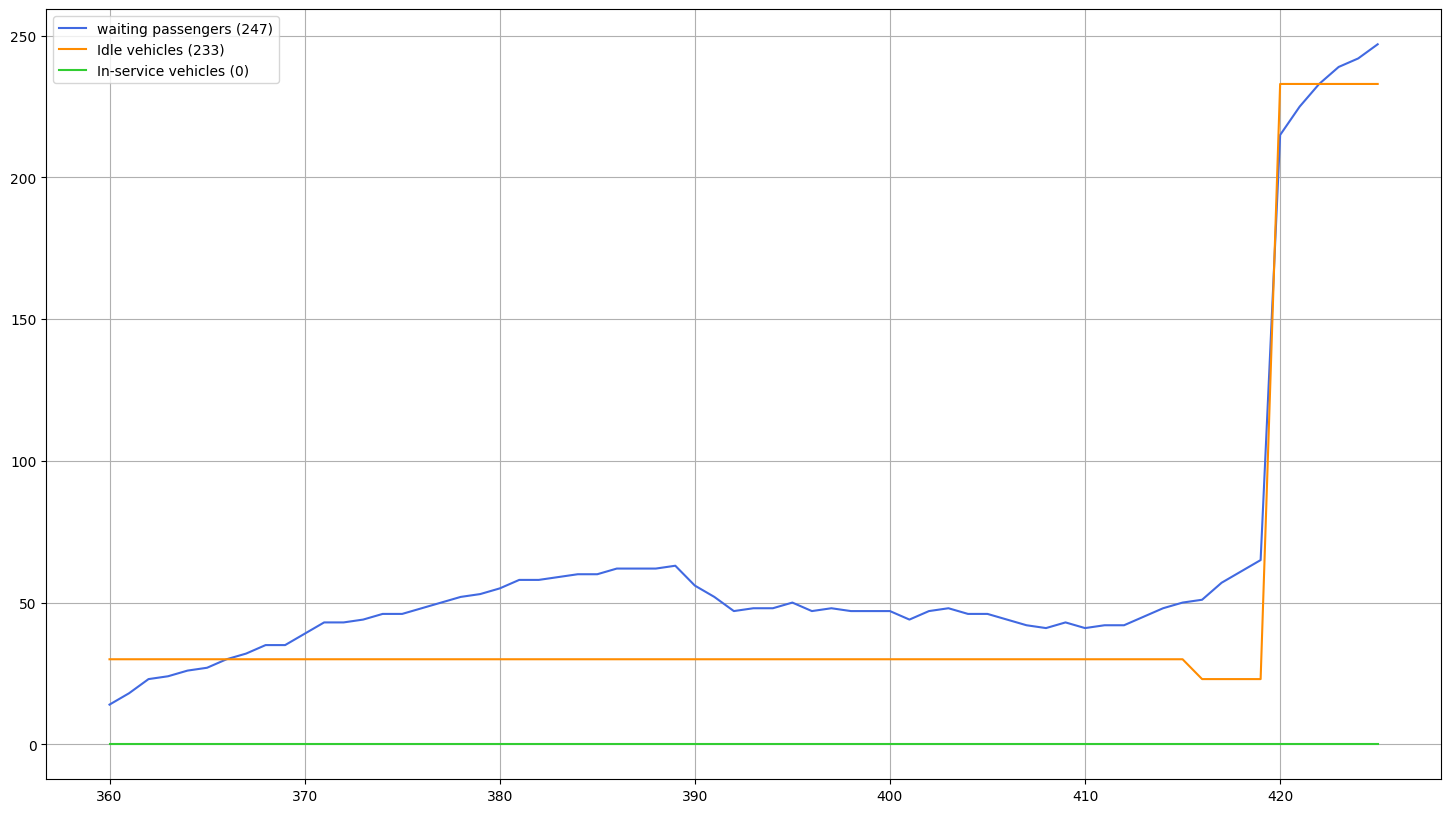

  6%|███████▍                                                                                                                  | 66/1080 [1:52:26<234:16:17, 831.73s/it]

In [ ]:
### Simulate
scene_1 = Simulator(passengers=passengers, vehicles=vehicles, configs=simul_configs)
scene_1.run()
print("done")

---

- **Generate generate configuraions for simulation**

In [ ]:
from module.simulator_helper import generate_simulation_result_json
import os

passengers = pd.read_json(os.path.join(simul_configs['save_path'], 'passenger_marker.json'))
trip = pd.read_json(os.path.join(simul_configs['save_path'], 'trip.json'))
records = pd.read_csv(os.path.join(simul_configs['save_path'], 'record.csv'))
print("done")
results = generate_simulation_result_json(passengers, trip, records)
results.to_json(os.path.join(simul_configs['save_path'], 'result.json'), orient='records')
print("results saved")

- **Generate figures and configurations for dashboard**

In [ ]:
from module.dashboard import dashboard_config
from module.dashboard import generate_dashboard_materials

In [ ]:
generate_dashboard_materials(dashboard_config)
print("✅ Dashboard materials generated successfully.")

In [ ]:
# # Cell 1: Imports and basic setup
# import warnings
# import traceback
# from pathlib import Path
# import pandas as pd
# import nest_asyncio
# import numpy as np
# # Fix asyncio issues for nbconvert
# nest_asyncio.apply()

# # Ignore warnings
# warnings.filterwarnings('ignore')


In [ ]:
# # Cell 2: Import helper modules
# from module.simulator_helper import (
#     base_configs,
#     generate_path_to_save,
#     get_preprocessed_seoul_data,
#     base_data,
#     checking_progress,
#     update_passenger,
#     update_vehicle,
#     dispatch_in_order,
#     generate_simulation_result_json,
#     osrm_routing_machine 
# )
# from module.dashboard import dashboard_config, generate_dashboard_materials


In [ ]:
# # Cell 3: Set dashboard region boundary file path
# dashboard_config['region_boundary_file_path'] = str(
#     Path('./data/etc/HangJeongDong_ver20230701.geojson').resolve()
# )


In [ ]:
# # Cell 4: Load and preprocess agent data
# passengers = pd.read_csv('./data/agents/passenger/passenger_data.csv')
# vehicles = pd.read_csv('./data/agents/vehicle/vehicle_data.csv')

# # Preprocess data (convert times, lat/lon columns, etc.)
# passengers, vehicles = get_preprocessed_seoul_data(passengers, vehicles)


In [ ]:
# # Cell 5: Configure simulation
# simul_configs = base_configs.copy()
# simul_configs['additional_path'] = 'scenario_base'
# simul_configs['dispatch_mode'] = 'in_order'
# simul_configs['save_path'] = str(Path('./simul_result') / simul_configs['additional_path'])
# Path(simul_configs['save_path']).mkdir(parents=True, exist_ok=True)

# # Attach preprocessed agent data to configs
# simul_configs['passenger_data'] = passengers
# simul_configs['vehicle_data'] = vehicles


In [ ]:
# import pandas as pd
# import numpy as np
# from multiprocess import Pool

# # Dummy placeholders for external functions; replace with real implementations
# def dispatch_cost_matrix(passengers, vehicles, time, configs):
#     # Returns a simple distance matrix (Euclidean distance)
#     matrix = np.sqrt(
#         (passengers['ride_lat'].values[:, None] - vehicles['lat'].values[None, :])**2 +
#         (passengers['ride_lon'].values[:, None] - vehicles['lon'].values[None, :])**2
#     )
#     return matrix

# def in_order_dispatch(active_ps, empty_vh, time, simul_configs):
#     vehicle_iloc, passenger_iloc, iloc_distance = [], [], []
#     for idx, row in active_ps.iterrows():
#         if len(empty_vh) == 0:
#             break
#         distances = np.sqrt((row['ride_lat'] - empty_vh['lat'])**2 + (row['ride_lon'] - empty_vh['lon'])**2)
#         vehicle_idx = distances.idxmin()
#         vehicle_iloc.append(vehicle_idx)
#         passenger_iloc.append(idx)
#         iloc_distance.append(distances[vehicle_idx])
#         empty_vh = empty_vh.drop(vehicle_idx)
#     return {'vehicle': vehicle_iloc, 'passenger': passenger_iloc, 'distance': iloc_distance}

# def ortools_dispatch(passengers, vehicles, cost_matrix):
#     # Simple in-order dispatch placeholder
#     return in_order_dispatch(passengers, vehicles, 0, None)

# def address_current_active_vehicle(current_active_vehicle, time, save_path, simul_configs):
#     # Simple placeholder: set trip time
#     travel_time = simul_configs.get('default_trip_time', 15)
#     add_board = simul_configs.get('add_board_time', 5)
#     add_disembark = simul_configs.get('add_disembark_time', 5)
#     current_active_vehicle['P_disembark_time'] = time + travel_time + add_board + add_disembark
#     return current_active_vehicle

# def dispatch_methods(requested_passenger, empty_vehicle, simul_configs, time):
#     if simul_configs.get('dispatch_mode','in_order') == 'optimization':
#         cost_matrix = dispatch_cost_matrix(requested_passenger, empty_vehicle, time, simul_configs)
#         dispatch_result = ortools_dispatch(requested_passenger, empty_vehicle, cost_matrix)
#     else:
#         dispatch_result = in_order_dispatch(requested_passenger, empty_vehicle, time, simul_configs)

#     dispatched_vehicles = empty_vehicle.iloc[dispatch_result['vehicle']].reset_index(drop=True)
#     dispatched_passengers = requested_passenger.iloc[dispatch_result['passenger']].reset_index(drop=True)

#     # Merge into active vehicles
#     current_active_vehicle = pd.concat([dispatched_vehicles, dispatched_passengers], axis=1)
#     current_active_vehicle = current_active_vehicle.rename(columns={
#         'ID':'P_ID', 'ride_lat':'P_ride_lat', 'ride_lon':'P_ride_lon',
#         'alight_lat':'P_alight_lat','alight_lon':'P_alight_lon',
#         'ride_time':'P_request_time'
#     })
#     current_active_vehicle['P_disembark_time'] = 0

#     empty_vehicle = empty_vehicle.drop(dispatched_vehicles.index).reset_index(drop=True)
#     requested_passenger = requested_passenger.drop(dispatched_passengers.index).reset_index(drop=True)

#     return requested_passenger, empty_vehicle, current_active_vehicle

# # ------------------------
# # Simulator Class
# # ------------------------
# class Simulator:
#     def __init__(self, passengers, vehicles, configs):
#         self.passengers = passengers.copy()
#         self.vehicles = vehicles.copy()
#         self.configs = configs.copy()

#         self.passengers['dispatch_time'] = 0

#         self.empty_vehicle = self.vehicles.copy()
#         self.active_vehicle = pd.DataFrame(columns=self.empty_vehicle.columns.tolist() + [
#             'P_ID','P_ride_lat','P_ride_lon','P_alight_lat','P_alight_lon','P_request_time','P_disembark_time'])
#         self.requested_passenger = pd.DataFrame(columns=self.passengers.columns)
#         self.fail_passenger = pd.DataFrame(columns=self.passengers.columns)
#         self.trips = pd.DataFrame(columns=['vehicle_id','passenger_id','start_time','end_time','origin','destination'])

#         self.max_dispatch_per_step = configs.get('max_dispatch', 5)
#         self.dispatch_interval = configs.get('dispatch_interval', 1)
#         self.last_dispatch_time = -self.dispatch_interval

#     # ------------------------
#     # Update passengers
#     # ------------------------
#     def update_passengers(self, current_time):
#         fail_time = self.configs.get('fail_time', 30)

#         new_requests = self.passengers[self.passengers['ride_time'] <= current_time]
#         self.passengers = self.passengers[self.passengers['ride_time'] > current_time].reset_index(drop=True)

#         if len(new_requests) > 0:
#             self.requested_passenger = pd.concat([self.requested_passenger, new_requests], ignore_index=True)

#         if len(self.requested_passenger) > 0:
#             self.requested_passenger['dispatch_time'] += 1
#             failed_mask = self.requested_passenger['dispatch_time'] >= fail_time
#             if failed_mask.any():
#                 failed_passengers = self.requested_passenger.loc[failed_mask]
#                 self.fail_passenger = pd.concat([self.fail_passenger, failed_passengers], ignore_index=True)
#                 self.requested_passenger = self.requested_passenger.loc[~failed_mask].reset_index(drop=True)

#     # ------------------------
#     # Update vehicles
#     # ------------------------
#     def update_vehicles(self, current_time):
#         if len(self.active_vehicle) == 0:
#             return
#         finished_mask = self.active_vehicle['P_disembark_time'] <= current_time
#         if finished_mask.any():
#             finished_vehicles = self.active_vehicle.loc[finished_mask].copy()
#             finished_vehicles['lat'] = finished_vehicles['P_alight_lat']
#             finished_vehicles['lon'] = finished_vehicles['P_alight_lon']
#             cols = ['P_ID','P_ride_lat','P_ride_lon','P_alight_lat','P_alight_lon','P_request_time','P_disembark_time']
#             finished_vehicles[cols] = np.nan
#             self.empty_vehicle = pd.concat([self.empty_vehicle, finished_vehicles], ignore_index=True)
#             self.active_vehicle = self.active_vehicle.loc[~finished_mask].reset_index(drop=True)

#     # ------------------------
#     # Dispatch passengers
#     # ------------------------
#     def dispatch_passengers(self, current_time):
#         if current_time - self.last_dispatch_time < self.dispatch_interval:
#             return
#         self.last_dispatch_time = current_time
#         if len(self.requested_passenger) == 0 or len(self.empty_vehicle) == 0:
#             return

#         save_path = self.configs.get('save_path','./')

#         # Wheelchair priority
#         A_requested = self.requested_passenger[self.requested_passenger['type']==1].reset_index(drop=True)
#         B_requested = self.requested_passenger[self.requested_passenger['type']==0].reset_index(drop=True)
#         A_empty = self.empty_vehicle[self.empty_vehicle['cartype']==1].reset_index(drop=True)
#         B_empty = self.empty_vehicle[self.empty_vehicle['cartype']==0].reset_index(drop=True)

#         dispatched_vehicles = pd.DataFrame()
#         dispatched_passengers = pd.DataFrame()

#         if len(A_requested) > 0 and len(A_empty) > 0:
#             A_requested, A_empty, A_current_active = dispatch_methods(A_requested, A_empty, self.configs, current_time)
#             self.empty_vehicle = pd.concat([A_empty, B_empty]).reset_index(drop=True)
#             dispatched_passengers = pd.concat([dispatched_passengers, A_requested])
#             dispatched_vehicles = pd.concat([dispatched_vehicles, A_current_active])

#         if len(B_requested) > 0 and len(self.empty_vehicle) > 0:
#             B_requested, B_empty, B_current_active = dispatch_methods(B_requested, self.empty_vehicle, self.configs, current_time)
#             self.empty_vehicle = B_empty
#             dispatched_passengers = pd.concat([dispatched_passengers, B_requested])
#             dispatched_vehicles = pd.concat([dispatched_vehicles, B_current_active])

#         self.requested_passenger = self.requested_passenger.loc[~self.requested_passenger['ID'].isin(dispatched_passengers['ID'])].reset_index(drop=True)
#         if len(dispatched_vehicles) > 0:
#             dispatched_vehicles = address_current_active_vehicle(dispatched_vehicles, current_time, save_path, self.configs)
#             self.active_vehicle = pd.concat([self.active_vehicle, dispatched_vehicles]).reset_index(drop=True)

#     # ------------------------
#     # Run simulation
#     # ------------------------
#     def run(self):
#         start_time, end_time = self.configs.get('time_range', [0, 1440])
#         for t in range(start_time, end_time):
#             self.update_passengers(t)
#             self.update_vehicles(t)
#             self.dispatch_passengers(t)
#             print(f"[DEBUG] t={t}: waiting={len(self.requested_passenger)}, idle={len(self.empty_vehicle)}, active={len(self.active_vehicle)}")


In [ ]:
# # Cell 7: Instantiate simulator
# scene = Simulator(passengers=passengers, vehicles=vehicles, configs=simul_configs)


In [ ]:
# # Cell 8: Run the simulation
# try:
#     print("Starting simulation...")
#     scene.run()
#     print("Simulation completed successfully!")
# except Exception:
#     print("Simulation failed:")
#     traceback.print_exc()


In [ ]:
# # Cell 9: Save results
# latest_sim_folder = Path(scene.configs['save_path'])

# # Generate simulation result JSON
# results_df = generate_simulation_result_json(
#     passengers=scene.requested_passenger,
#     trips=scene.trips,
#     records=scene.simulation_record,
#     time_range=scene.configs['time_range']
# )

# results_df.to_json(latest_sim_folder / 'result.json', orient='records')
# print(f"Results saved to: {latest_sim_folder / 'result.json'}")

# # Save passenger markers and trips as JSON

# # Save all results once
# save_json_data(scene.fail_markers_all, latest_sim_folder, 'passenger_marker')
# save_json_data(scene.trips, latest_sim_folder, 'trip')
# results = generate_simulation_result_json(scene.requested_passenger, scene.trips, scene.simulation_record)
# results.to_json(latest_sim_folder / 'result.json', orient='records')


In [ ]:
# # Cell 10: Generate dashboard
# try:
#     generate_dashboard_materials(dashboard_config)
#     print("Dashboard generation completed successfully!")
# except Exception:
#     print("Dashboard generation failed:")
#     traceback.print_exc()
